In [3]:

import pandas as pd
import matplotlib.pyplot as plt

print("Bienvenue dans l'analyse Big Data de Pedali.ma !")


Bienvenue dans l'analyse Big Data de Pedali.ma !


In [4]:

import pandas as pd
from pathlib import Path

# Chemin vers les données du projet
fichier = Path("../data/trips_history.jsonl")

# Charger les 50 000 trajets
df = pd.read_json(fichier, lines=True)

# Afficher le nombre de trajets
print("Nombre total de trajets :", len(df))

# Afficher les 5 premiers trajets
display(df.head())


Nombre total de trajets : 50000


,trip_id,station_depart,station_arrivee,date_depart,duree_minutes
0,1,Hay Riad,Souissi,2026-11-07T10:47:05.439300,47
1,2,Hassan,Ocean,2026-11-07T01:00:05.439488,10
2,3,Hassan,Hay Riad,2026-11-03T04:48:05.439547,25
3,4,Hassan,Hay Riad,2026-11-04T12:14:05.439614,58
4,5,Hay Riad,Souissi,2026-11-03T23:48:05.439702,40


In [5]:

import pandas as pd
from pathlib import Path

# Localiser le fichier des trajets
fichier = Path("../data/trips_history.jsonl")

# Lire les données
df = pd.read_json(fichier, lines=True)

# Afficher les résultats
print("Nombre total de trajets :", len(df))
display(df.head())


Nombre total de trajets : 50000


,trip_id,station_depart,station_arrivee,date_depart,duree_minutes
0,1,Hay Riad,Souissi,2026-11-07T10:47:05.439300,47
1,2,Hassan,Ocean,2026-11-07T01:00:05.439488,10
2,3,Hassan,Hay Riad,2026-11-03T04:48:05.439547,25
3,4,Hassan,Hay Riad,2026-11-04T12:14:05.439614,58
4,5,Hay Riad,Souissi,2026-11-03T23:48:05.439702,40


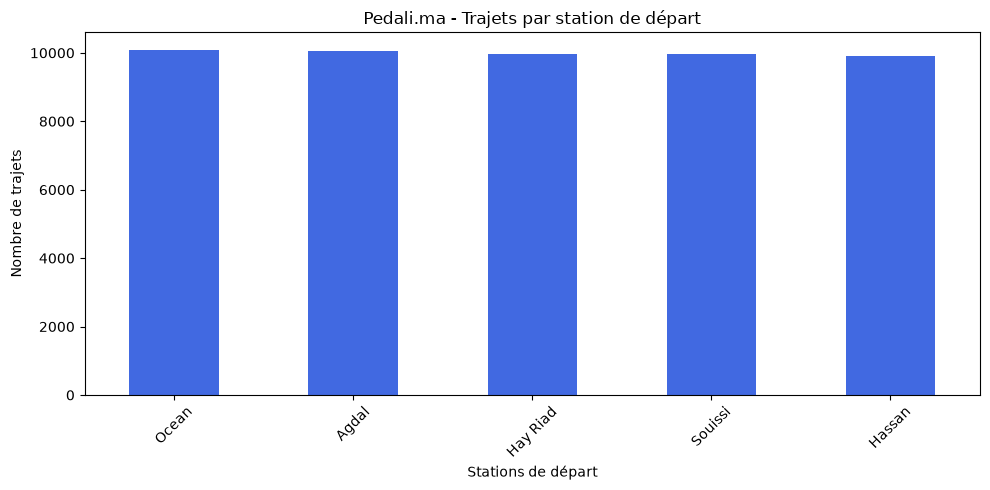

In [6]:

# Compter les trajets par station de départ
stations = df["station_depart"].value_counts()

# Créer le graphique
plt.figure(figsize=(10, 5))

stations.plot(kind="bar", color="royalblue")

plt.title("Pedali.ma - Trajets par station de départ")
plt.xlabel("Stations de départ")
plt.ylabel("Nombre de trajets")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()


Durée moyenne des trajets : 32.45 minutes


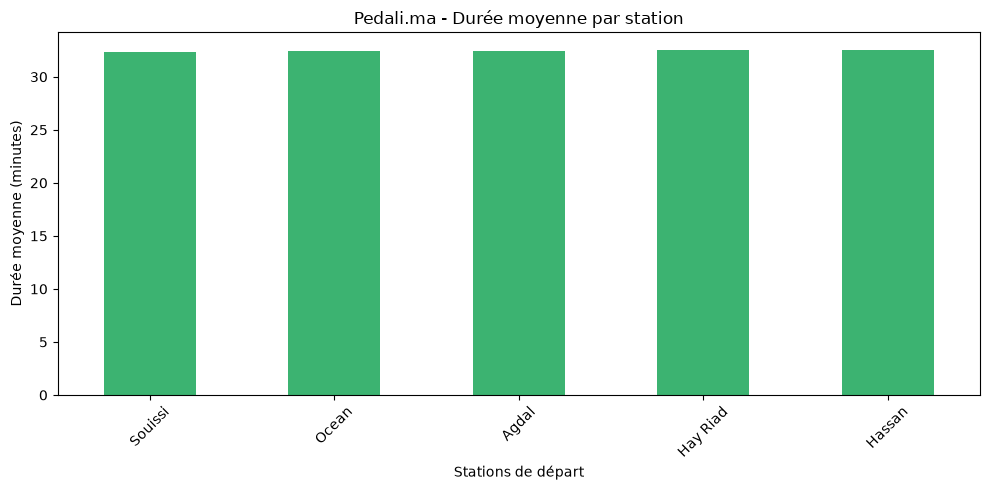

In [7]:

# Calculer la durée moyenne de tous les trajets
moyenne = df["duree_minutes"].mean()

print(f"Durée moyenne des trajets : {moyenne:.2f} minutes")

# Durée moyenne par station de départ
durees = df.groupby("station_depart")["duree_minutes"].mean()

# Créer le graphique
plt.figure(figsize=(10, 5))

durees.sort_values().plot(
    kind="bar",
    color="mediumseagreen"
)

plt.title("Pedali.ma - Durée moyenne par station")
plt.xlabel("Stations de départ")
plt.ylabel("Durée moyenne (minutes)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()


Top 10 des itinéraires les plus fréquents :


station_depart  station_arrivee
Agdal           Hay Riad           2587
Ocean           Souissi            2564
Hay Riad        Agdal              2562
Ocean           Agdal              2551
Souissi         Hay Riad           2533
Hassan          Hay Riad           2529
Agdal           Souissi            2520
Hay Riad        Souissi            2512
Ocean           Hay Riad           2500
Souissi         Hassan             2485
dtype: int64

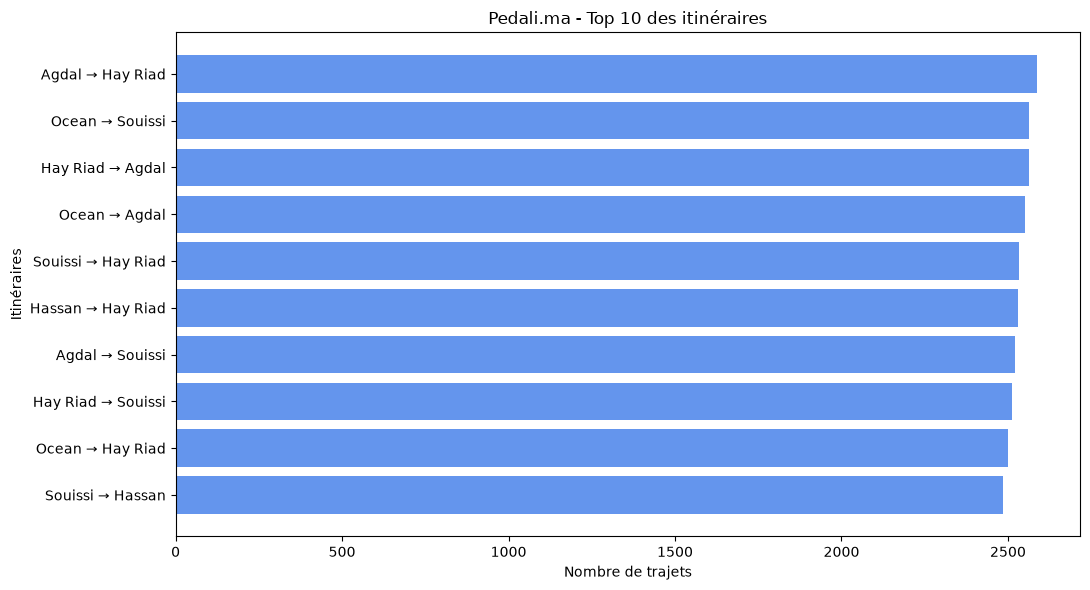

In [8]:

# Compter les trajets entre les stations
trajets = (
    df.groupby(["station_depart", "station_arrivee"])
    .size()
    .sort_values(ascending=False)
    .head(10)
)

# Afficher les résultats
print("Top 10 des itinéraires les plus fréquents :")
display(trajets)

# Préparer les noms des itinéraires
noms = [
    f"{depart} → {arrivee}"
    for depart, arrivee in trajets.index
]

# Créer le graphique
plt.figure(figsize=(11, 6))
plt.barh(noms, trajets.values, color="cornflowerblue")
plt.gca().invert_yaxis()

plt.title("Pedali.ma - Top 10 des itinéraires")
plt.xlabel("Nombre de trajets")
plt.ylabel("Itinéraires")
plt.tight_layout()
plt.show()


Nombre de jours analysés : 8


date_depart
2026-11-02     936
2026-11-03    7108
2026-11-04    7202
2026-11-05    7140
2026-11-06    7286
dtype: int64

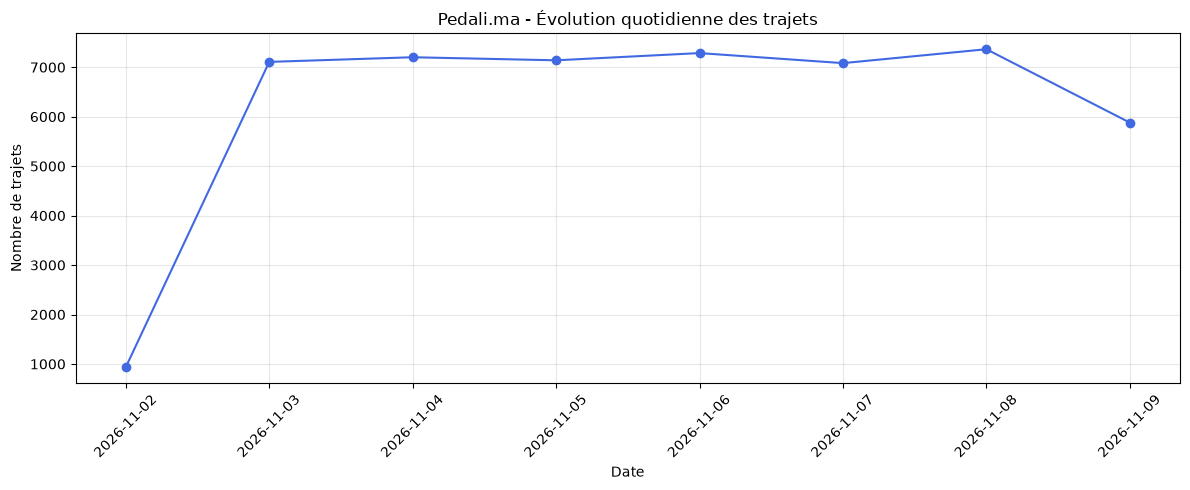

In [9]:

# Convertir les dates au format datetime
df["date_depart"] = pd.to_datetime(df["date_depart"])

# Compter le nombre de trajets par jour
trajets_jour = (
    df.groupby(df["date_depart"].dt.date)
    .size()
    .sort_index()
)

# Afficher les premiers résultats
print("Nombre de jours analysés :", len(trajets_jour))
display(trajets_jour.head())

# Créer le graphique
plt.figure(figsize=(12, 5))

plt.plot(
    trajets_jour.index,
    trajets_jour.values,
    marker="o",
    color="royalblue"
)

plt.title("Pedali.ma - Évolution quotidienne des trajets")
plt.xlabel("Date")
plt.ylabel("Nombre de trajets")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()


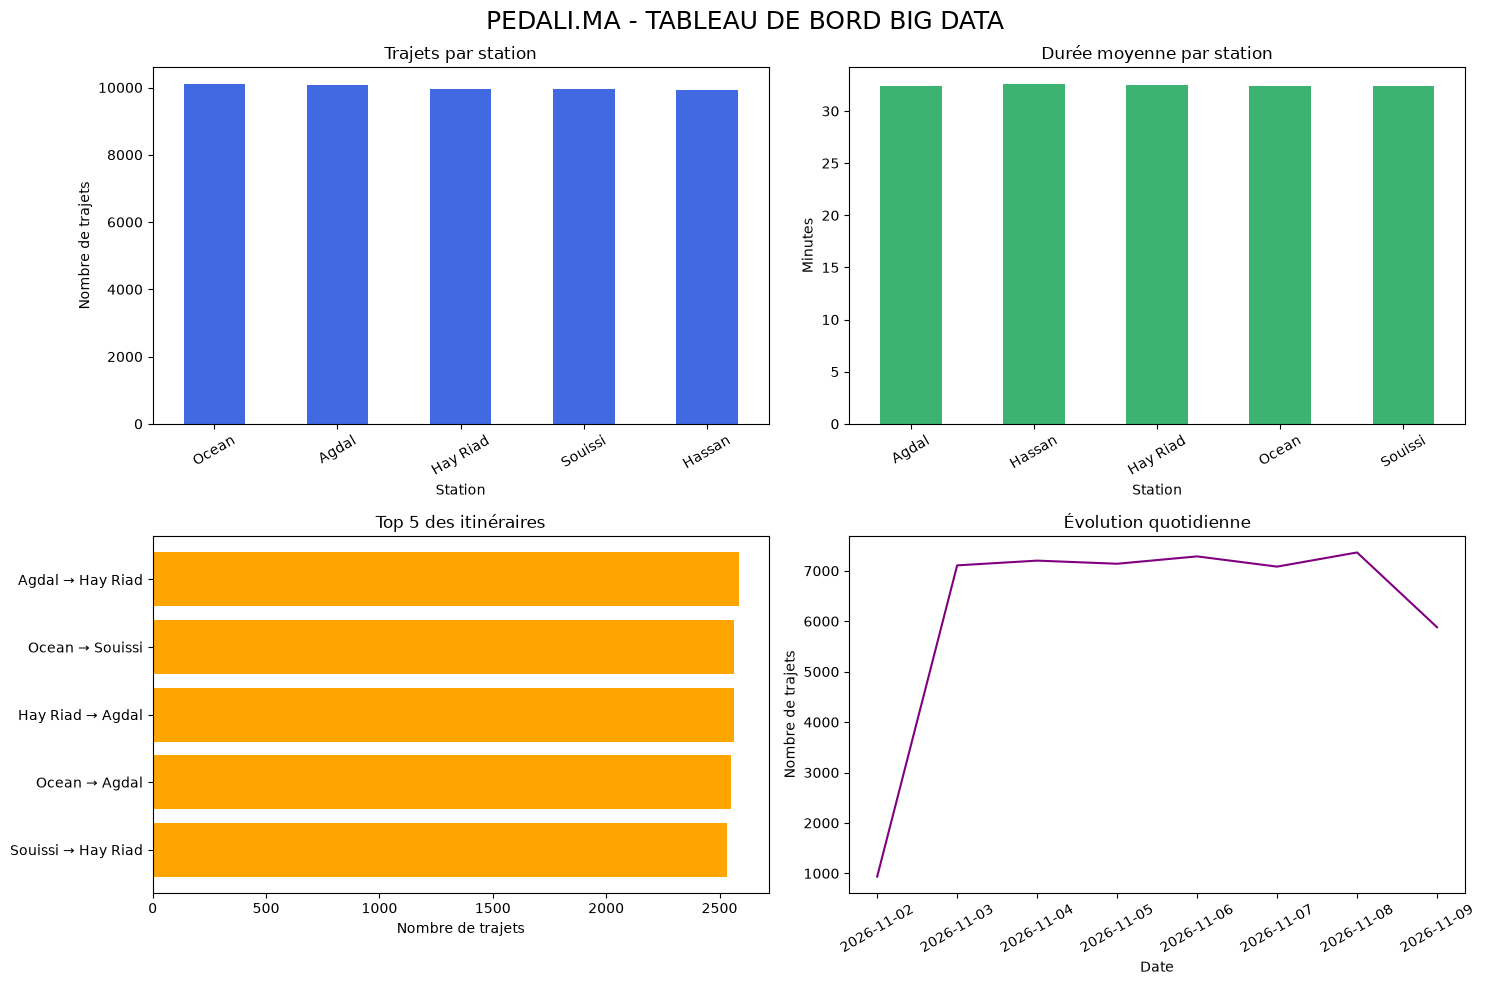

In [11]:

# Tableau de bord Pedali.ma
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Trajets par station
df["station_depart"].value_counts().plot(
    kind="bar", ax=axes[0, 0], color="royalblue"
)
axes[0, 0].set_title("Trajets par station")
axes[0, 0].set_xlabel("Station")
axes[0, 0].set_ylabel("Nombre de trajets")
axes[0, 0].tick_params(axis="x", rotation=30)

# 2. Durée moyenne par station
df.groupby("station_depart")["duree_minutes"].mean().plot(
    kind="bar", ax=axes[0, 1], color="mediumseagreen"
)
axes[0, 1].set_title("Durée moyenne par station")
axes[0, 1].set_xlabel("Station")
axes[0, 1].set_ylabel("Minutes")
axes[0, 1].tick_params(axis="x", rotation=30)

# 3. Top 5 des itinéraires
top5 = (
    df.groupby(["station_depart", "station_arrivee"])
    .size()
    .nlargest(5)
)
noms = [f"{a} → {b}" for a, b in top5.index]

axes[1, 0].barh(noms, top5.values, color="orange")
axes[1, 0].invert_yaxis()
axes[1, 0].set_title("Top 5 des itinéraires")
axes[1, 0].set_xlabel("Nombre de trajets")

# 4. Évolution quotidienne
axes[1, 1].plot(
    trajets_jour.index,
    trajets_jour.values,
    color="purple"
)
axes[1, 1].set_title("Évolution quotidienne")
axes[1, 1].set_xlabel("Date")
axes[1, 1].set_ylabel("Nombre de trajets")
axes[1, 1].tick_params(axis="x", rotation=30)

fig.suptitle("PEDALI.MA - TABLEAU DE BORD BIG DATA", fontsize=18)
plt.tight_layout()

fig.savefig("../data/dashboard_pedali.png", dpi=300, bbox_inches="tight")
plt.show()
